# Handwritten Digit Prediction using Artificial Neural Network (ANN)

This project uses **TensorFlow and Keras** to build an Artificial Neural Network that recognizes handwritten digits from the MNIST dataset.

The goal is to train a model that can classify grayscale images of handwritten digits into one of **10 classes (0–9)**.

**Model type:** Fully connected Artificial Neural Network  
**Dataset:** MNIST  
**Framework:** TensorFlow / Keras


## 1. Import Libraries

Import the libraries required for loading and processing the dataset, building the neural network, evaluating its predictions, and visualizing results.


In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten, Input
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from pathlib import Path

tf.keras.utils.set_random_seed(42)


## 2. Load the MNIST Dataset

MNIST is a collection of handwritten digit images.

- **Training set:** 60,000 images
- **Testing set:** 10,000 images
- **Image size:** 28 × 28 pixels
- **Classes:** Digits from 0 to 9

Keras downloads the dataset automatically if it is not already available locally.


In [2]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


## 3. Explore the Dataset

Check the dimensions of the training and testing data. Each image contains 28 × 28 pixel values, and each label represents the actual digit.


In [3]:
print("Training images shape:", X_train.shape)
print("Training labels shape:", y_train.shape)
print("Testing images shape:", X_test.shape)
print("Testing labels shape:", y_test.shape)


Training images shape: (60000, 28, 28)
Training labels shape: (60000,)
Testing images shape: (10000, 28, 28)
Testing labels shape: (10000,)


### Visualize a Sample Image

Display one image from the training dataset along with its actual label.


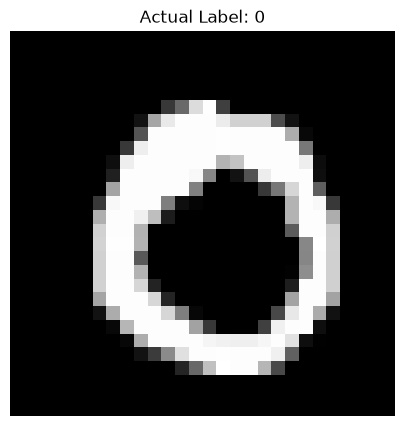

In [4]:
plt.figure(figsize=(5, 5))
plt.imshow(X_train[56], cmap="gray")
plt.title(f"Actual Label: {y_train[56]}")
plt.axis("off")
plt.show()


## 4. Data Preprocessing

The pixel values in the original images range from **0 to 255**. Normalize them to the range **0 to 1** by dividing by 255.

This makes the input values smaller and helps the neural network train more effectively. The labels are already integer class values, so they do not need one-hot encoding when using sparse categorical cross-entropy.


In [5]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())


Minimum pixel value: 0.0
Maximum pixel value: 1.0


## 5. Build the Artificial Neural Network

Create a Sequential model with the following layers:

| Layer | Configuration | Purpose |
|---|---|---|
| Input | 28 × 28 | Receives the input image |
| Flatten | — | Converts the 2D image into a 1D vector |
| Dense | 128 neurons, ReLU | Learns patterns from the input |
| Dense | 32 neurons, ReLU | Learns additional feature combinations |
| Dense | 10 neurons, Softmax | Outputs probabilities for digits 0–9 |

The output layer uses **Softmax** because this is a multi-class classification problem.


In [6]:
model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation="relu"),
    Dense(32, activation="relu"),
    Dense(10, activation="softmax")
])


### Model Summary

Display the architecture and number of trainable parameters.


In [7]:
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,938 (409.91 KB)

 Trainable params: 104,938 (409.91 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Compile the Model

Before training, configure the model with:

- **Optimizer:** Adam
- **Loss function:** Sparse categorical cross-entropy
- **Metric:** Accuracy

Sparse categorical cross-entropy is suitable because the target labels are integer values from 0 to 9.


In [8]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


## 7. Train the Model

Train the ANN using the training images and labels.

A validation split of 20% means that Keras keeps 20% of the training data for validation during training. This validation data is not used to update the model's weights.


In [9]:
history = model.fit(
    X_train,
    y_train,
    epochs=25,
    batch_size=32,
    validation_split=0.2
)


Epoch 1/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9180 - loss: 0.2872 - val_accuracy: 0.9569 - val_loss: 0.1517
Epoch 2/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9637 - loss: 0.1230 - val_accuracy: 0.9647 - val_loss: 0.1188
Epoch 3/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9754 - loss: 0.0830 - val_accuracy: 0.9672 - val_loss: 0.1120
Epoch 4/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9822 - loss: 0.0597 - val_accuracy: 0.9702 - val_loss: 0.1039
Epoch 5/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9868 - loss: 0.0441 - val_accuracy: 0.9701 - val_loss: 0.1141
Epoch 6/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9896 - loss: 0.0346 - val_accuracy: 0.9678 - val_loss: 0.1313
Epoch 7/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9916 - loss: 0.0272 - val_accuracy: 0.9724 - val_loss: 0.1204
Epoch 8/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9917 - loss: 0.0252 - 

## 8. Evaluate the Model

Evaluate the trained model on the separate test dataset. The test set was not used during training.

The model returns a probability distribution for each image. `argmax()` selects the class with the highest predicted probability.


In [10]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)

y_prob = model.predict(X_test, verbose=0)
y_pred = y_prob.argmax(axis=1)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")


Test Loss: 0.1430
Test Accuracy: 0.9762
Test Accuracy: 97.62%


### Classification Report

The classification report provides precision, recall and F1-score for each digit class.


In [11]:
print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.98      0.99      0.99      1135
           2       0.98      0.96      0.97      1032
           3       0.96      0.98      0.97      1010
           4       0.98      0.98      0.98       982
           5       0.99      0.96      0.98       892
           6       0.98      0.98      0.98       958
           7       0.98      0.97      0.97      1028
           8       0.96      0.98      0.97       974
           9       0.97      0.97      0.97      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



### Confusion Matrix

A confusion matrix shows how many examples of each digit were classified correctly or incorrectly.


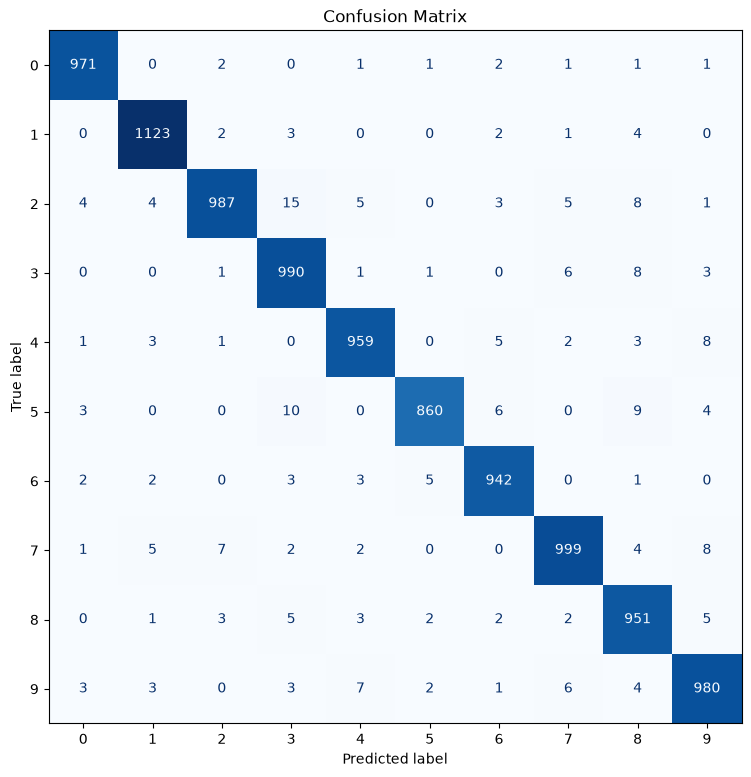

In [12]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(9, 9))
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)
display.plot(cmap="Blues", ax=ax, colorbar=False)
plt.title("Confusion Matrix")
plt.show()


## 9. Visualize Training Performance

The training history contains the loss and accuracy values recorded after each epoch. Comparing training and validation curves helps us understand how the model performed during training.


### Training and Validation Loss

Lower loss indicates that the model's predictions are closer to the expected labels.


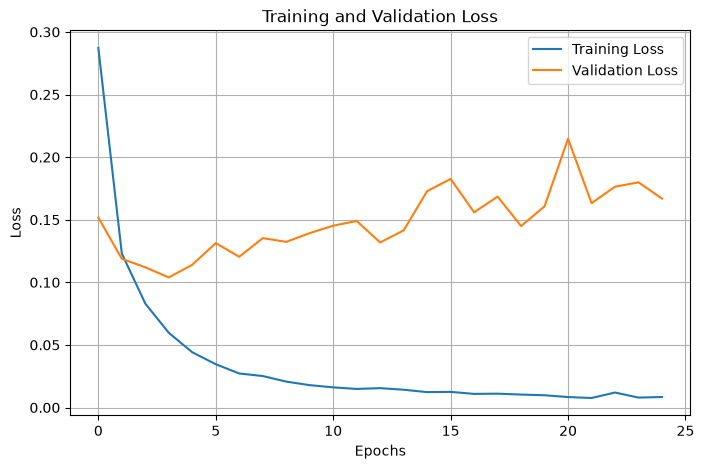

In [13]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


### Training and Validation Accuracy

Accuracy represents the proportion of correctly classified images.


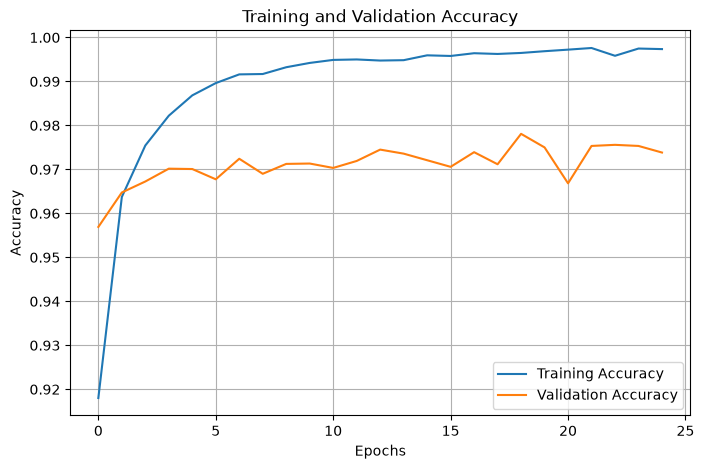

In [14]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


## 10. Test a Prediction

Select an image from the test dataset and compare the model's prediction with the actual label.

The model expects a batch of images, so `reshape(1, 28, 28)` adds a batch dimension to the selected image.


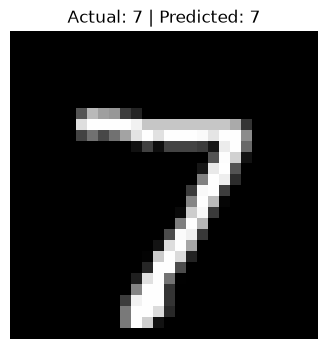

Actual Label: 7
Predicted Label: 7
Prediction Confidence: 100.00%


In [15]:
index = 0

image = X_test[index]
actual_label = y_test[index]

prediction_probabilities = model.predict(
    image.reshape(1, 28, 28),
    verbose=0
)

predicted_label = prediction_probabilities.argmax(axis=1)[0]
confidence = prediction_probabilities.max()

plt.figure(figsize=(4, 4))
plt.imshow(image, cmap="gray")
plt.title(f"Actual: {actual_label} | Predicted: {predicted_label}")
plt.axis("off")
plt.show()

print("Actual Label:", actual_label)
print("Predicted Label:", predicted_label)
print(f"Prediction Confidence: {confidence * 100:.2f}%")


## 11. Save the Trained Model

Save the trained neural network in the native **Keras `.keras` format**. The `models` directory is created automatically if it does not already exist.

After running this cell, the trained model will be available at `models/handwritten_digit_ann.keras`. You can load this file later without training the model again.


In [16]:
model_dir = Path("models")
model_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "handwritten_digit_ann.keras"
model.save(model_path)

print(f"Model saved successfully at: {model_path}")


Model saved successfully at: models\handwritten_digit_ann.keras


## 12. Load the Saved Model

Load the saved model and use it to make a prediction. This demonstrates that the model can be reused after training.

The input image must be preprocessed in the same way as the training images.


In [21]:
loaded_model = keras.models.load_model(model_path)

loaded_prediction = loaded_model.predict(
    X_test[78].reshape(1, 28, 28),
    verbose=0
).argmax(axis=1)[0]

print("Prediction from loaded model:", loaded_prediction)
print("Actual Label:", y_test[78])


Prediction from loaded model: 9
Actual Label: 9


## Conclusion

In this project, an Artificial Neural Network was built and trained to classify handwritten digits using the MNIST dataset.

The workflow covered dataset loading, image normalization, ANN construction, model training, evaluation, visualization, prediction, and saving/loading the trained model.

This is a basic fully connected ANN practice project. A Convolutional Neural Network (CNN) can be explored separately to learn how convolution and pooling layers work with image data.
